In [63]:
import tensorflow as tf 
import numpy as np 
import matplotlib.pyplot as plt 
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
from tensorflow.keras.layers import Dropout
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error
from tensorflow.keras.optimizers import Adam


# Generate data

In [64]:
X_train = np.linspace(-1,1,20)


In [65]:
y_train=np.array([-0.6561,-0.3099,-0.59035,-0.50855,-0.285,
                  -0.2443,-0.02445,0.00135, -0.2006, 0.07475, 
                  -0.1422,0.06515,0.15265,0.3521, 0.28415,
                  0.5524,0.23115,0.20835,0.4211,0.60485])

In [66]:

X_test=np.linspace(-1,1,20)

In [67]:
y_test=np.array([-0.69415,-0.451,-0.43005,-0.4484,-0.1475,
                 -0.5019,-0.28055,0.24595,-0.21425,-0.0286,
                 0.23415,0.46575,0.07955,0.1973,0.0719,
                 0.3639,0.5536,0.3365,0.50705,0.33435])

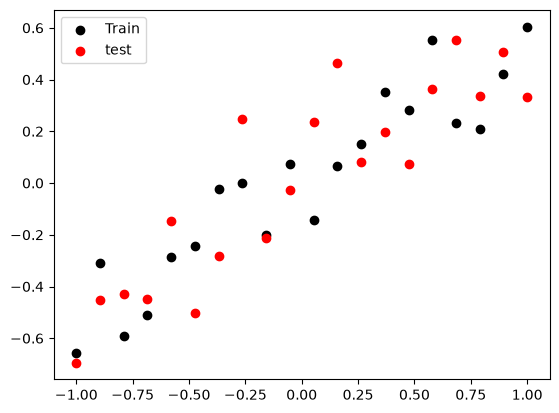

In [68]:
plt.scatter(X_train, y_train , c='black', label='Train')
plt.scatter(X_test, y_test, c='red',label="test")
plt.legend()
plt.show()

# Regression model


In [69]:
## Applying regression

model=Sequential()

model.add(Dense(128, input_dim=1, activation='relu'))
model.add(Dense(128, activation='relu'))
model.add(Dense(1, activation='linear'))

adam=Adam(learning_rate=0.1)
model.compile(loss='mse',optimizer=adam,metrics=['mse'])
history=model.fit(X_train, y_train, epochs=500, validation_data=(X_test, y_test), verbose=0)

In [70]:
# evaluate the model
_, train_mse=model.evaluate(X_train , y_train, verbose=0)
_, test_mse=model.evaluate(X_test , y_test, verbose=0)
print('Train : {}, Test : {}'.format(train_mse, test_mse))

Train : 0.0172820333391428, Test : 0.031569212675094604


In [71]:
y_pred=model.predict(X_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 233ms/step


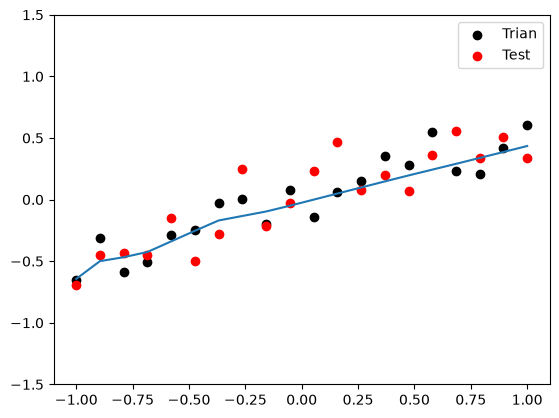

In [72]:
plt.figure()
plt.scatter(X_train , y_train, c='black', label="Trian")
plt.scatter(X_test,y_test,c='red', label='Test')
plt.plot(X_test,y_pred)
plt.legend()
plt.ylim(-1.5, 1.5)
plt.show()

C:\Users\HP\AppData\Local\Temp\ipykernel_20296\848098724.py:3: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


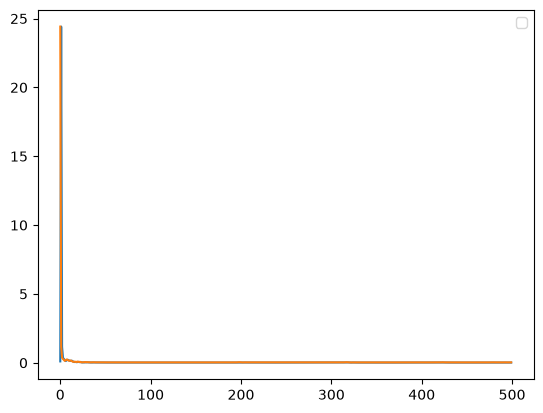

In [73]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.legend()
plt.show()

#in our graph we can see that our model overfitting
--> we solve it using dropout


# Dropout Model

In [79]:
model=Sequential()

model.add(Dense(128, input_dim=1, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(128, activation='relu'))
model.add(Dropout(0.5))
model.add(Dense(1, activation='linear'))

adam=Adam(learning_rate=0.01)

model.compile(loss='mse', optimizer=adam, metrics=['mse'])

history=model.fit(X_train, y_train , epochs=500, validation_data=(X_test, y_test), verbose=False)

In [80]:
# Evaluating the model

_, train_mse=model.evaluate(X_train, y_train)
_, test_mse=model.evaluate(X_test,y_test)
print("train : {}, test : {}".format(train_mse, test_mse))

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step - loss: 0.0173 - mse: 0.0173
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step - loss: 0.0399 - mse: 0.0399
train : 0.01730790175497532, test : 0.03994930908083916


In [81]:
y_pred=model.predict(X_test)

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step   


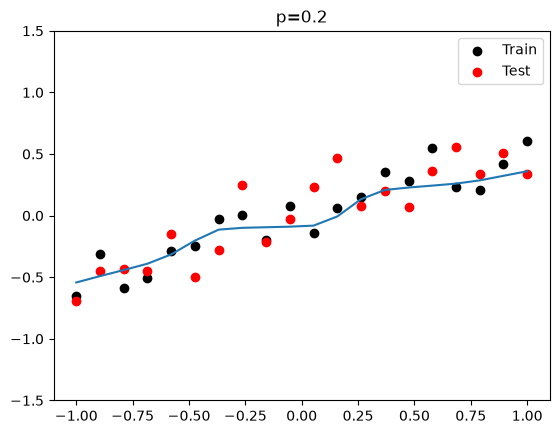

In [82]:
plt.figure()
plt.title('p=0.2')
plt.scatter(X_train,y_train, c='black',label='Train')
plt.scatter(X_test, y_test, c='red', label="Test")
plt.plot(X_test, y_pred)
plt.legend()
plt.ylim(-1.5, 1.5)
plt.show()

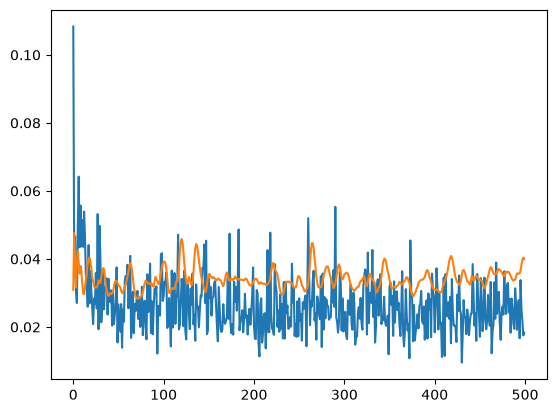

In [83]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])